# Experiment 1 analysis: learning curves and the small-data regime

This notebook analyses results/tables/experiment_1.csv. It first reports mean and sample standard deviation over repeated runs for every dataset, model, training size, and recorded metric. It then shows a two-dataset-column by six-metric-row learning-curve grid and several views focused on the central question: how do neural-network and Gaussian-process approaches compare when data are scarce?

Method families used in the focused comparisons:

- Pure GP: exact GP and sparse GP variants
- Pure NN: deep ensemble and MC dropout
- Hybrid: DKL (shown in model-level plots but kept separate from the pure-family comparison)

Lower is better for RMSE, NLL, CRPS, training time, and inference time. For coverage, closeness to the nominal 0.90 target is better.

In [8]:
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_rows", 200)
pd.set_option("display.max_columns", 30)

# Work whether the kernel starts in the repository root or in notebooks/.
DATA_CANDIDATES = [
    Path("results/tables/experiment_1.csv"),
    Path("../results/tables/experiment_1.csv"),
]
DATA_PATH = next((path for path in DATA_CANDIDATES if path.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Could not find results/tables/experiment_1_lr_05.csv")

results = pd.read_csv(DATA_PATH)
results = results[results["model"] != "mc_dropout_standard"].copy()

METRICS = [
    "rmse",
    "nll",
    "crps",
    "coverage_90",
    "final_training_time_seconds",
    "inference_time_seconds",
]
REQUIRED = {"dataset", "split", "train_size", "model", *METRICS}
missing = REQUIRED.difference(results.columns)
if missing:
    raise ValueError(f"Missing required columns: {sorted(missing)}")

results["train_size"] = pd.to_numeric(results["train_size"])
for metric in METRICS:
    results[metric] = pd.to_numeric(results[metric], errors="coerce")

DATASETS = sorted(results["dataset"].dropna().unique())
TRAIN_SIZES = sorted(results["train_size"].dropna().unique())
MODEL_ORDER = [
    model for model in [
        "exact_gp", "sparse_gp_m16", "sparse_gp_m64", "sparse_gp_m256",
        "deep_ensemble", "mc_dropout", "dkl",
    ] if model in set(results["model"])
]
MODEL_ORDER += sorted(set(results["model"]) - set(MODEL_ORDER))

MODEL_LABELS = {
    "exact_gp": "Exact GP",
    "sparse_gp_m16": "Sparse GP (m=16)",
    "sparse_gp_m64": "Sparse GP (m=64)",
    "sparse_gp_m256": "Sparse GP (m=256)",
    "deep_ensemble": "Deep ensemble",
    "mc_dropout": "MC dropout (heteroscedastic)",
    "dkl": "DKL (hybrid)",
}
MODEL_COLORS = dict(zip(MODEL_ORDER, sns.color_palette("tab10", n_colors=len(MODEL_ORDER))))
MODEL_MARKERS = dict(zip(MODEL_ORDER, ["o", "s", "^", "D", "P", "X", "v", "*"][:len(MODEL_ORDER)]))
MODEL_LINESTYLES = dict(zip(MODEL_ORDER, ["-", "--", "-.", ":", (0, (5, 1)), (0, (3, 1, 1, 1)), (0, (1, 1)), (0, (5, 2, 1, 2))][:len(MODEL_ORDER)]))
GP_MODELS = [m for m in MODEL_ORDER if m == "exact_gp" or m.startswith("sparse_gp")]
NN_MODELS = [m for m in MODEL_ORDER if m in {"deep_ensemble", "mc_dropout"}]

print(f"Loaded {len(results):,} rows from {DATA_PATH.resolve()}")
print(f"Datasets: {len(DATASETS)} | models: {len(MODEL_ORDER)} | train sizes: {TRAIN_SIZES}")


Loaded 2,700 rows from /Users/paulbahde/Desktop/UncertaintyQuantification/results/tables/experiment_1.csv
Datasets: 3 | models: 7 | train sizes: [50, 100, 200, 400, 800, 1600, 3200]


In [9]:
# Export all six metrics as mean ± standard deviation over repeated runs.
from IPython.display import FileLink

metrics_mean_std = (
    results.groupby(["dataset", "model", "train_size"], observed=True)[METRICS]
    .agg(["mean", "std"])
    .sort_index()
)
metrics_mean_std.columns = [
    f"{metric}_{statistic}" for metric, statistic in metrics_mean_std.columns
]
metrics_mean_std = metrics_mean_std.reset_index()

METRICS_SUMMARY_CSV = DATA_PATH.resolve().with_name(
    "experiment_1_metrics_mean_std.csv"
)
metrics_mean_std.to_csv(METRICS_SUMMARY_CSV, index=False)

try:
    download_path = METRICS_SUMMARY_CSV.relative_to(Path.cwd())
except ValueError:
    download_path = METRICS_SUMMARY_CSV

print(f"Saved {len(metrics_mean_std):,} summary rows to {METRICS_SUMMARY_CSV}")
display(metrics_mean_std)

Saved 135 summary rows to /Users/paulbahde/Desktop/UncertaintyQuantification/results/tables/experiment_1_metrics_mean_std.csv


,dataset,model,train_size,rmse_mean,rmse_std,nll_mean,nll_std,crps_mean,crps_std,coverage_90_mean,coverage_90_std,final_training_time_seconds_mean,final_training_time_seconds_std,inference_time_seconds_mean,inference_time_seconds_std
0,combined_cycle_power_plant,deep_ensemble,50,4.808846,0.252342,3.564499,0.418371,2.764884,0.151101,0.751202,0.063915,5.724980,1.258155,0.001392,0.000138
1,combined_cycle_power_plant,deep_ensemble,100,4.610254,0.209543,3.024882,0.069406,2.593848,0.123724,0.896447,0.035254,3.030818,0.368814,0.001355,0.000112
2,combined_cycle_power_plant,deep_ensemble,200,4.324814,0.132052,2.930236,0.052482,2.396763,0.058745,0.877377,0.028590,5.885547,1.035581,0.001350,0.000097
3,combined_cycle_power_plant,deep_ensemble,400,4.229238,0.104671,2.877845,0.035004,2.330610,0.034890,0.889368,0.018981,11.734575,1.963969,0.001364,0.000148
4,combined_cycle_power_plant,deep_ensemble,800,4.184534,0.109408,2.853088,0.025523,2.300806,0.037644,0.910188,0.013590,12.322533,1.492268,0.001331,0.000075
5,combined_cycle_power_plant,deep_ensemble,1600,4.148802,0.107992,2.836313,0.026002,2.274977,0.037265,0.917006,0.010712,16.184566,1.669911,0.001401,0.000193
6,combined_cycle_power_plant,deep_ensemble,3200,4.119600,0.109303,2.825091,0.024798,2.257034,0.031538,0.919880,0.009271,28.936818,2.643816,0.001322,0.000057
7,combined_cycle_power_plant,dkl,50,5.928504,0.659624,4.555322,1.446192,3.511157,0.449608,0.607053,0.119091,0.241311,0.050531,0.054135,0.004121
8,combined_cycle_power_plant,dkl,100,5.295209,0.486306,3.526478,0.362511,3.021393,0.280646,0.700052,0.063143,0.279479,0.054766,0.055995,0.003917
9,combined_cycle_power_plant,dkl,200,4.736098,0.285765,3.092363,0.130522,2.641135,0.143419,0.804154,0.044083,0.418200,0.102824,0.065724,0.003076


## Mean ± standard deviation over runs

The table below is grouped by dataset, model, and training size. Every metric is summarized over splits/runs with its arithmetic mean and sample standard deviation (pandas ddof=1). The run count is included to make missing or unbalanced cells visible.

In [10]:
summary = (
    results.groupby(["dataset", "model", "train_size"], observed=True)
    .agg(
        runs=("split", "nunique"),
        **{
            f"{metric}_{stat}": (metric, stat)
            for metric in METRICS
            for stat in ("mean", "std")
        },
    )
    .sort_index()
)

## Learning curves for paper

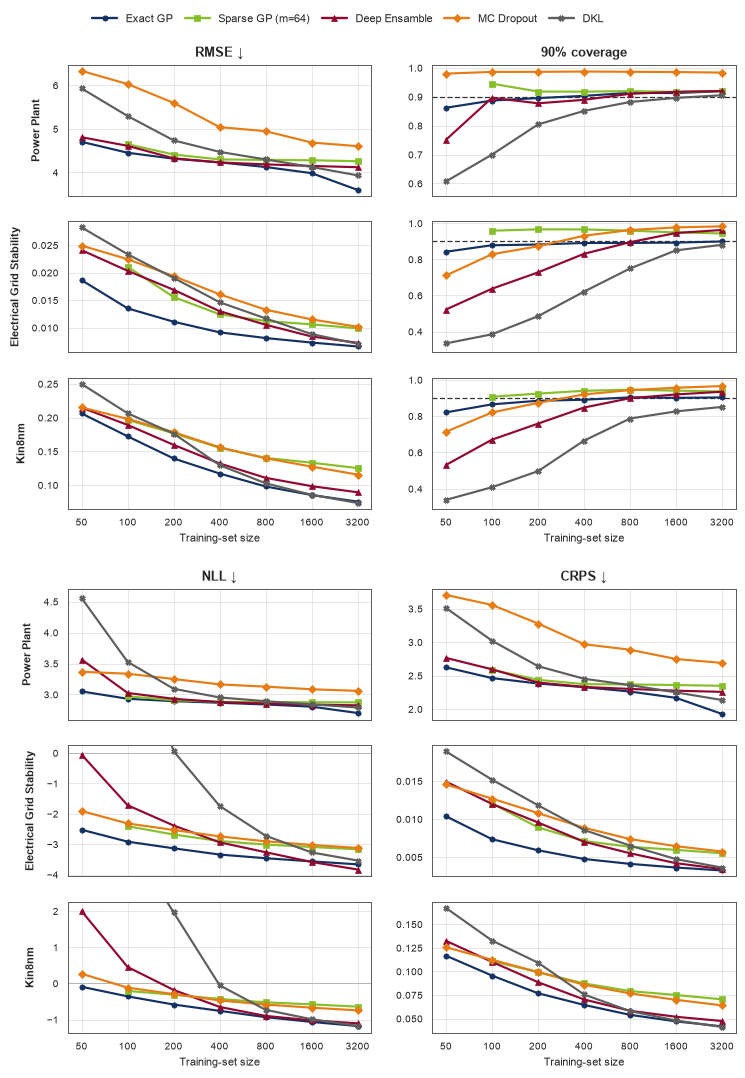

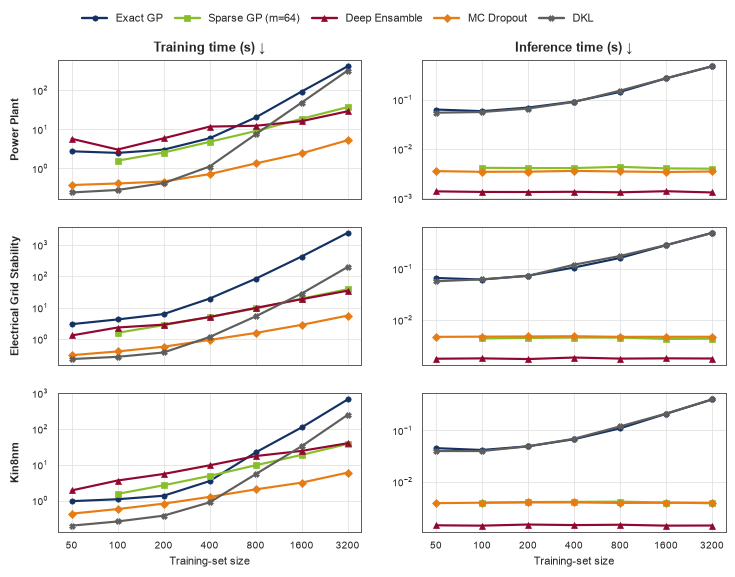

Saved two-column alternatives to /Users/paulbahde/Desktop/UncertaintyQuantification/results/figures/experiment_1


In [11]:
from matplotlib.ticker import LogFormatterMathtext, LogLocator, NullLocator

PAPER_FIGURE_DIR = DATA_PATH.resolve().parents[1] / "figures" / "experiment_1"
PAPER_FIGURE_DIR.mkdir(parents=True, exist_ok=True)
curve_stats = (
    results.groupby(["dataset", "model", "train_size"], observed=True)[METRICS]
    .agg(["mean", "std"])
    .sort_index()
)
PAPER_MODEL_COLORS = {
    "exact_gp": "#143163",
    "sparse_gp_m64": "#87BF2A",
    "deep_ensemble": "#910730",
    "mc_dropout": "#E67C13",
    "dkl": "#5E5E5D",
}

def _robust_panel_limits(series_by_model, *, log_y=False):
    transformed = {
        model: np.log10(values) if log_y else values
        for model, values in series_by_model.items()
    }
    model_medians = {
        model: np.median(values) for model, values in transformed.items()
    }
    ordered = sorted(model_medians.items(), key=lambda item: item[1])
    minimum_visible = int(np.ceil(0.6 * len(ordered)))
    split_at, strongest_gap = len(ordered), 0.0
    for candidate in range(minimum_visible, len(ordered)):
        lower_values = np.array([value for _, value in ordered[:candidate]])
        gap = ordered[candidate][1] - ordered[candidate - 1][1]
        lower_spread = max(lower_values[-1] - lower_values[0], 1e-9)
        if gap > max(0.35 * lower_spread, 0.05) and gap > strongest_gap:
            strongest_gap, split_at = gap, candidate
    visible_models = [model for model, _ in ordered[:split_at]]
    all_values = np.concatenate(list(transformed.values()))
    visible_values = np.concatenate([transformed[m] for m in visible_models])
    lower, upper = all_values.min(), visible_values.max()
    span = max(upper - lower, 1e-9)
    lower, upper = lower - 0.06 * span, upper + 0.08 * span
    if log_y:
        return 10 ** np.floor(lower), 10 ** upper
    return lower, upper

def plot_paper_curve(
    ax, dataset, metric, *, log_y=False, robust=False, models=None,
    marker_map=None, line_styles=None,
):
    models = list(PAPER_MODEL_COLORS) if models is None else models
    series_by_model = {}
    for model_idx, model in enumerate(models):
        try:
            current = curve_stats.loc[(dataset, model)]
        except KeyError:
            continue
        x = current.index.to_numpy(dtype=float)
        y = current[(metric, "mean")].to_numpy(dtype=float)
        valid = np.isfinite(x) & np.isfinite(y)
        x, y = x[valid], y[valid]
        series_by_model[model] = y
        ax.plot(
            x, y, color=PAPER_MODEL_COLORS[model],
            linestyle=line_styles[model], linewidth=1.55,
            marker=marker_map[model], markersize=3.8, markeredgewidth=0.5,
            zorder=2 + model_idx,
        )
    ax.set_xscale("log", base=2)
    ax.set_xticks(TRAIN_SIZES)
    ax.set_xticklabels([f"{int(size)}" for size in TRAIN_SIZES])
    if log_y:
        ax.set_yscale("log")
        ax.yaxis.set_major_locator(LogLocator(base=10, subs=(1.0,)))
        ax.yaxis.set_major_formatter(LogFormatterMathtext(base=10))
        ax.yaxis.set_minor_locator(NullLocator())
    if robust and series_by_model:
        ax.set_ylim(*_robust_panel_limits(series_by_model, log_y=log_y))
    ax.grid(True, which="major", color="0.88", linewidth=0.55)
    ax.grid(False, which="minor")
    ax.tick_params(axis="both", labelsize=7.5, length=3)
    for spine in ax.spines.values():
        spine.set_linewidth(0.7)
        spine.set_color("0.35")

TWO_COLUMN_MODELS = [
    "exact_gp", "sparse_gp_m64", "deep_ensemble", "mc_dropout", "dkl"
]
TWO_COLUMN_MODEL_LABELS = {
    "exact_gp": "Exact GP",
    "sparse_gp_m64": "Sparse GP (m=64)",
    "deep_ensemble": "Deep Ensamble",
    "mc_dropout": "MC Dropout",
    "dkl": "DKL",
}
TWO_COLUMN_MARKERS = {
    "exact_gp": "o",
    "sparse_gp_m64": "s",
    "deep_ensemble": "^",
    "mc_dropout": "D",
    "dkl": "X",
}
TWO_COLUMN_LINESTYLES = {model: "-" for model in TWO_COLUMN_MODELS}
TWO_COLUMN_DATASET_LABELS = {
    "combined_cycle_power_plant": "Power Plant",
    "electrical_grid_stability": "Electrical Grid Stability",
    "kin8nm": "Kin8nm",
}
two_column_handles = [
    Line2D(
        [0], [0], color=PAPER_MODEL_COLORS[model],
        linestyle=TWO_COLUMN_LINESTYLES[model], linewidth=1.7,
        marker=TWO_COLUMN_MARKERS[model], markersize=3.8, markeredgewidth=0.5,
        label=TWO_COLUMN_MODEL_LABELS[model],
    )
    for model in TWO_COLUMN_MODELS
]

two_column_quality_blocks = [
    (("rmse", "RMSE ↓"), ("coverage_90", "90% coverage")),
    (("nll", "NLL ↓"), ("crps", "CRPS ↓")),
]

with plt.rc_context({"font.size": 8.5, "axes.titleweight": "semibold"}):
    fig = plt.figure(figsize=(8.0, 11.0))
    grid = fig.add_gridspec(
        2 * len(DATASETS) + 1, 2,
        height_ratios=[1, 1, 1, 0.22, 1, 1, 1],
        hspace=0.22, wspace=0.20,
    )
    for block_idx, columns in enumerate(two_column_quality_blocks):
        for dataset_idx, dataset in enumerate(DATASETS):
            row = block_idx * len(DATASETS) + dataset_idx
            grid_row = row if block_idx == 0 else row + 1
            for col, (metric, title) in enumerate(columns):
                ax = fig.add_subplot(grid[grid_row, col])
                plot_paper_curve(
                    ax, dataset, metric, robust=(metric == "nll"),
                    models=TWO_COLUMN_MODELS,
                    marker_map=TWO_COLUMN_MARKERS,
                    line_styles=TWO_COLUMN_LINESTYLES,
                )
                if dataset_idx == 0:
                    ax.set_title(title, fontsize=9.5, pad=6)
                if col == 0:
                    ax.set_ylabel(
                        TWO_COLUMN_DATASET_LABELS[dataset],
                        fontsize=8.2, fontweight="semibold", labelpad=8,
                    )
                if metric == "coverage_90":
                    ax.axhline(0.90, color="0.2", linestyle=(0, (4, 2)),
                               linewidth=0.9, zorder=1)
                    panel_values = np.concatenate([
                        curve_stats.loc[(dataset, model)][(metric, "mean")].to_numpy()
                        for model in TWO_COLUMN_MODELS
                        if (dataset, model) in curve_stats.index.droplevel(2)
                    ])
                    ax.set_ylim(max(0.0, np.nanmin(panel_values) - 0.05), 1.01)
                elif metric == "nll" and ax.get_ylim()[0] < 0 < ax.get_ylim()[1]:
                    ax.axhline(0.0, color="0.65", linewidth=0.55, zorder=1)
                if dataset_idx == len(DATASETS) - 1:
                    ax.set_xlabel("Training-set size", fontsize=8.2)
                else:
                    ax.tick_params(axis="x", labelbottom=False)

    fig.legend(
        handles=two_column_handles, loc="upper center",
        bbox_to_anchor=(0.5, 0.995), ncol=len(TWO_COLUMN_MODELS),
        frameon=False, columnspacing=1.1, handlelength=2.3, fontsize=7.8,
    )
    fig.subplots_adjust(top=0.94, bottom=0.06, left=0.15, right=0.985)
    quality_two_column_base = (
        PAPER_FIGURE_DIR / "paper_predictive_metrics_two_columns"
    )
    fig.savefig(quality_two_column_base.with_suffix(".pdf"), bbox_inches="tight")
    fig.savefig(quality_two_column_base.with_suffix(".png"), dpi=300,
                bbox_inches="tight")
    plt.show()

two_column_timing_metrics = [
    ("final_training_time_seconds", "Training time (s) ↓"),
    ("inference_time_seconds", "Inference time (s) ↓"),
]
with plt.rc_context({"font.size": 8.5, "axes.titleweight": "semibold"}):
    fig, axes = plt.subplots(
        len(DATASETS), 2, figsize=(8.0, 5.9),
        gridspec_kw={"hspace": 0.20, "wspace": 0.20}, squeeze=False,
    )
    for dataset_idx, dataset in enumerate(DATASETS):
        for col, (metric, title) in enumerate(two_column_timing_metrics):
            ax = axes[dataset_idx, col]
            plot_paper_curve(
                ax, dataset, metric, log_y=True, robust=False,
                models=TWO_COLUMN_MODELS,
                marker_map=TWO_COLUMN_MARKERS,
                line_styles=TWO_COLUMN_LINESTYLES,
            )
            if dataset_idx == 0:
                ax.set_title(title, fontsize=9.5, pad=6)
            if col == 0:
                ax.set_ylabel(
                    TWO_COLUMN_DATASET_LABELS[dataset],
                    fontsize=8.2, fontweight="semibold", labelpad=8,
                )
            if dataset_idx == len(DATASETS) - 1:
                ax.set_xlabel("Training-set size", fontsize=8.2)
            else:
                ax.tick_params(axis="x", labelbottom=False)

    fig.legend(
        handles=two_column_handles, loc="upper center",
        bbox_to_anchor=(0.5, 0.995), ncol=len(TWO_COLUMN_MODELS),
        frameon=False, columnspacing=1.1, handlelength=2.3, fontsize=7.8,
    )
    fig.subplots_adjust(top=0.90, bottom=0.10, left=0.15, right=0.985)
    timing_two_column_base = PAPER_FIGURE_DIR / "paper_timing_metrics_two_columns"
    fig.savefig(timing_two_column_base.with_suffix(".pdf"), bbox_inches="tight")
    fig.savefig(timing_two_column_base.with_suffix(".png"), dpi=300,
                bbox_inches="tight")
    plt.show()

print(f"Saved two-column alternatives to {PAPER_FIGURE_DIR}")

## Figures for appendix

One figure per metric, with the three datasets arranged vertically. All sparse-GP variants are included.

findfont: Failed to find font weight semibold for Arial, now using 700.


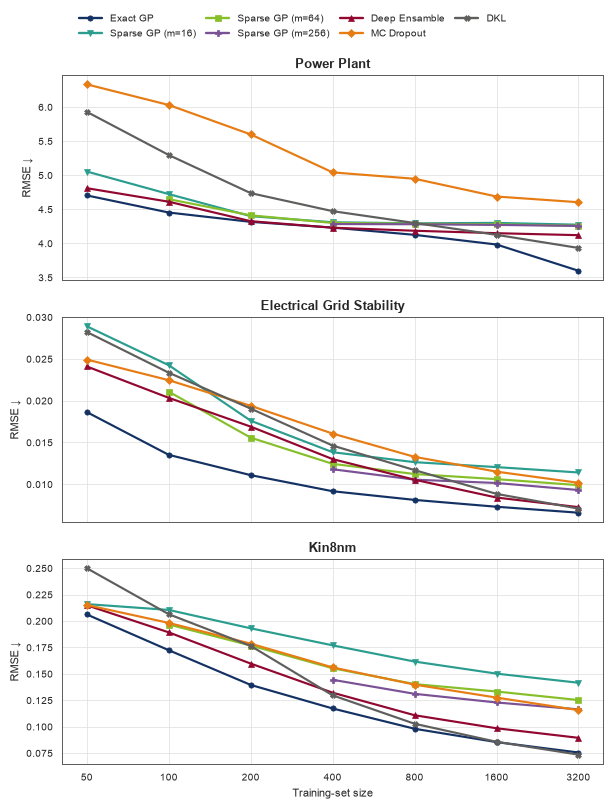

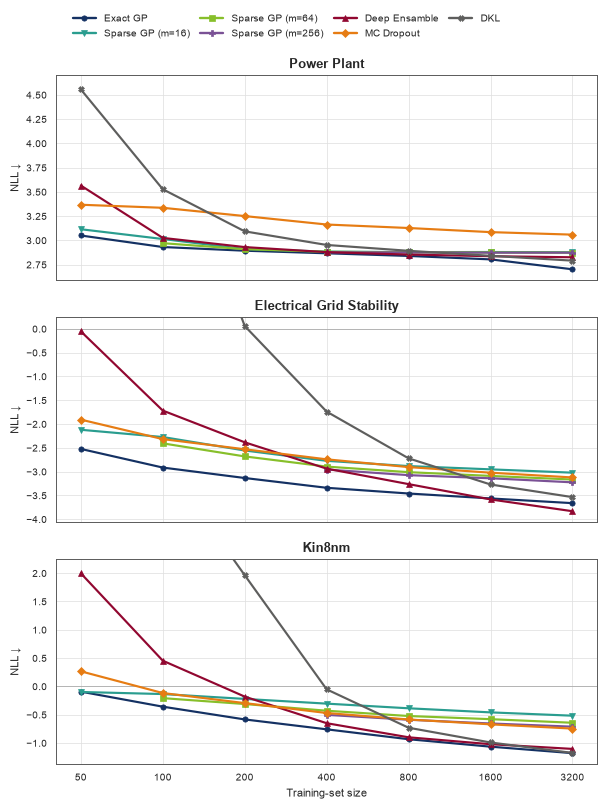

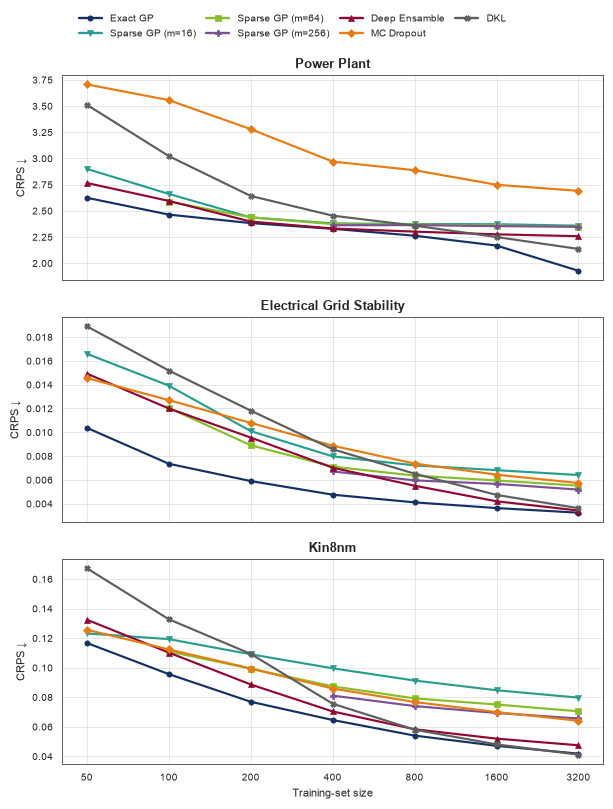

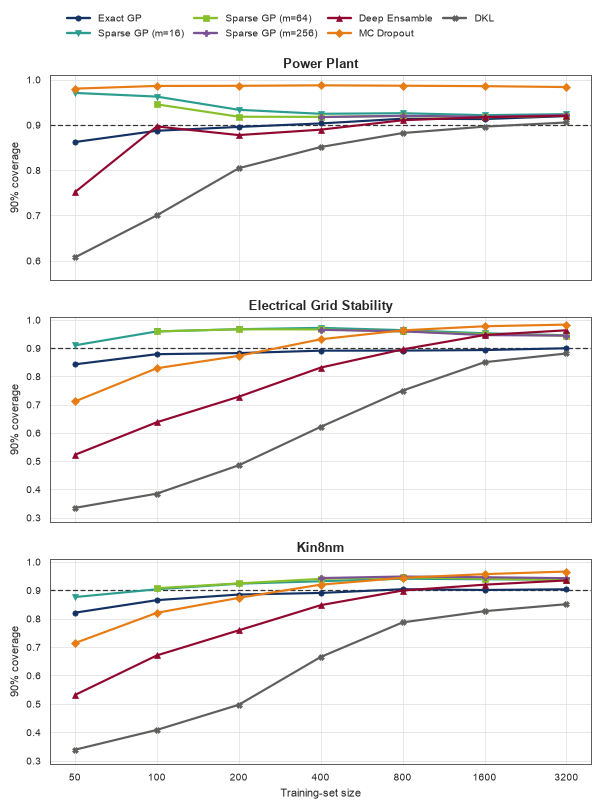

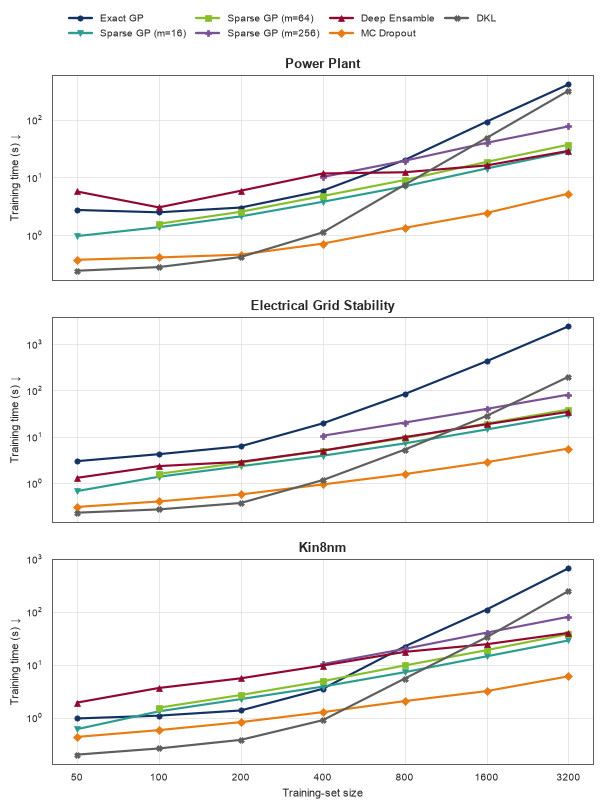

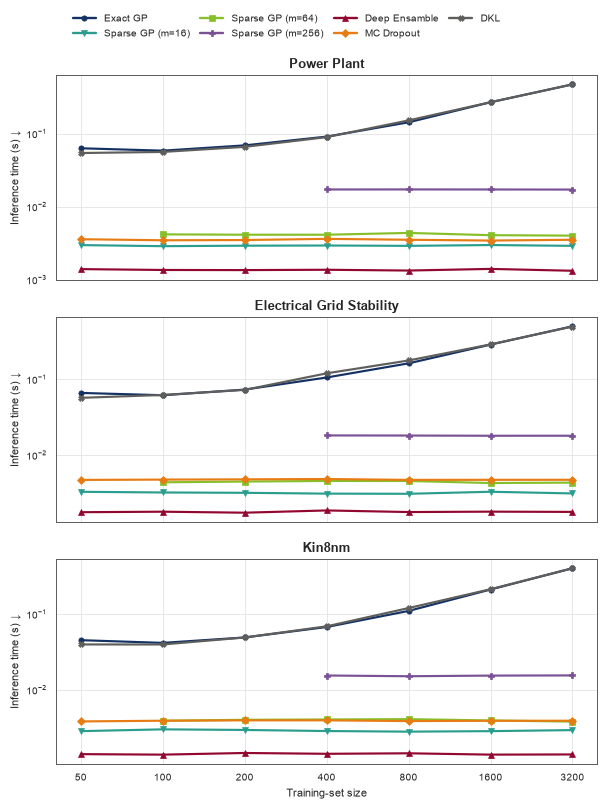

Saved 6 appendix figures as PDF and PNG to /Users/paulbahde/Desktop/UncertaintyQuantification/results/figures/experiment_1
appendix_rmse.pdf
appendix_rmse.png
appendix_nll.pdf
appendix_nll.png
appendix_crps.pdf
appendix_crps.png
appendix_coverage_90.pdf
appendix_coverage_90.png
appendix_final_training_time_seconds.pdf
appendix_final_training_time_seconds.png
appendix_inference_time_seconds.pdf
appendix_inference_time_seconds.png


In [12]:
APPENDIX_MODELS = [
    "exact_gp", "sparse_gp_m16", "sparse_gp_m64",
    "sparse_gp_m256", "deep_ensemble", "mc_dropout", "dkl",
]
APPENDIX_MODELS = [model for model in APPENDIX_MODELS if model in MODEL_ORDER]
APPENDIX_MODEL_LABELS = {
    "exact_gp": "Exact GP",
    "sparse_gp_m16": "Sparse GP (m=16)",
    "sparse_gp_m64": "Sparse GP (m=64)",
    "sparse_gp_m256": "Sparse GP (m=256)",
    "deep_ensemble": "Deep Ensamble",
    "mc_dropout": "MC Dropout",
    "dkl": "DKL",
}
APPENDIX_MODEL_COLORS = {
    "exact_gp": "#143163",       # navy
    "sparse_gp_m16": "#2A9D8F",  # teal
    "sparse_gp_m64": "#87BF2A",  # green accent
    "sparse_gp_m256": "#7A5195", # purple
    "deep_ensemble": "#910730",  # burgundy
    "mc_dropout": "#E67C13",     # orange accent
    "dkl": "#5E5E5D",            # dark gray
}
PAPER_MODEL_COLORS.update(APPENDIX_MODEL_COLORS)
APPENDIX_MARKERS = {
    "exact_gp": "o", "sparse_gp_m16": "v",
    "sparse_gp_m64": "s", "sparse_gp_m256": "P",
    "deep_ensemble": "^", "mc_dropout": "D", "dkl": "X",
}
APPENDIX_LINESTYLES = {model: "-" for model in APPENDIX_MODELS}
APPENDIX_METRICS = {
    "rmse": ("RMSE ↓", False),
    "nll": ("NLL ↓", False),
    "crps": ("CRPS ↓", False),
    "coverage_90": ("90% coverage", False),
    "final_training_time_seconds": ("Training time (s) ↓", True),
    "inference_time_seconds": ("Inference time (s) ↓", True),
}
appendix_handles = [
    Line2D(
        [0], [0], color=APPENDIX_MODEL_COLORS[model], linewidth=1.7,
        linestyle="-", marker=APPENDIX_MARKERS[model], markersize=3.8,
        markeredgewidth=0.5, label=APPENDIX_MODEL_LABELS[model],
    )
    for model in APPENDIX_MODELS
]

appendix_figure_paths = []
for metric, (metric_label, use_log_scale) in APPENDIX_METRICS.items():
    with plt.rc_context({"font.size": 8.5, "axes.titleweight": "semibold"}):
        fig, axes = plt.subplots(
            len(DATASETS), 1, figsize=(6.4, 8.3), sharex=True,
            gridspec_kw={"hspace": 0.18}, squeeze=False,
        )
        for dataset_idx, dataset in enumerate(DATASETS):
            ax = axes[dataset_idx, 0]
            plot_paper_curve(
                ax, dataset, metric, log_y=use_log_scale,
                robust=(metric == "nll"), models=APPENDIX_MODELS,
                marker_map=APPENDIX_MARKERS,
                line_styles=APPENDIX_LINESTYLES,
            )
            ax.set_title(TWO_COLUMN_DATASET_LABELS[dataset], fontsize=9.2, pad=5)
            ax.set_ylabel(metric_label, fontsize=8.2)
            if metric == "coverage_90":
                ax.axhline(
                    0.90, color="0.2", linestyle=(0, (4, 2)),
                    linewidth=0.9, zorder=1,
                )
                coverage_values = np.concatenate([
                    curve_stats.loc[(dataset, model)][(metric, "mean")].to_numpy()
                    for model in APPENDIX_MODELS
                    if (dataset, model) in curve_stats.index.droplevel(2)
                ])
                ax.set_ylim(max(0.0, np.nanmin(coverage_values) - 0.05), 1.01)
            elif metric == "nll" and ax.get_ylim()[0] < 0 < ax.get_ylim()[1]:
                ax.axhline(0.0, color="0.65", linewidth=0.55, zorder=1)
            if dataset_idx == len(DATASETS) - 1:
                ax.set_xlabel("Training-set size", fontsize=8.2)
            else:
                ax.tick_params(axis="x", labelbottom=False)

        fig.legend(
            handles=appendix_handles, loc="upper center",
            bbox_to_anchor=(0.5, 0.985), ncol=4, frameon=False,
            columnspacing=1.0, handlelength=2.2, fontsize=7.5,
        )
        fig.subplots_adjust(top=0.90, bottom=0.07, left=0.14, right=0.985)
        appendix_base = PAPER_FIGURE_DIR / f"appendix_{metric}"
        pdf_path = appendix_base.with_suffix(".pdf")
        png_path = appendix_base.with_suffix(".png")
        fig.savefig(pdf_path, bbox_inches="tight")
        fig.savefig(png_path, dpi=300, bbox_inches="tight")
        appendix_figure_paths.extend([pdf_path, png_path])
        plt.show()

print(f"Saved {len(APPENDIX_METRICS)} appendix figures as PDF and PNG to {PAPER_FIGURE_DIR}")
for path in appendix_figure_paths:
    print(path.name)